# GenMol - Basics

## Setup
This notebook assumes that the NIM is running! Ports for the NIMs:
- AlphaFold2: 8081
- MolMIM: 8082
- **GenMOL: 8083**
- diffdock : 8084


In [48]:
#!pip install safe-mol datamol pandas numpy rdkit matplotlib 2>/dev/null | tail -n 1

In [49]:
#!pip install safe-mol datamol 2>/dev/null | tail -n 1

In [50]:
from nv_genmol.genmol import GenMol_Generator
from nv_genmol.utils import Utils

from rdkit import Chem
from rdkit.Chem import Draw

# SAFE <> SMILES conversion
import safe as sf
import datamol as dm

import pandas as pd

GENMOL_HOST = 'http://127.0.0.1:8083'
gm = GenMol_Generator(invoke_url = f"{GENMOL_HOST}/generate")


## Test NIM availability

In [51]:
!curl {GENMOL_HOST}/v1/health/ready

true

## Define Seeds and used Seed for generation

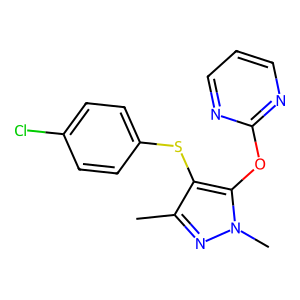

In [52]:
#Seed 1
m1 = "CC1=NN(C)C(OC2N=CC=CN=2)=C1SC1C=CC(Cl)=CC=1"
m1_name = "BCS-CM90960"

seed_mol_m1  = dm.to_mol(m1)
display(dm.to_image(seed_mol_m1))

In [53]:
# define the seed to be used in the notebook
m_seq = m1
seed_mol = seed_mol_m1

## check SAFE conversion & Reconstruction

In [54]:
safe_str = sf.encode(seed_mol)
print(f"SMILES: {m_seq}")
print(f"SAFE:   {safe_str}\n represented using {len(safe_str.split('.'))} fragments")

SMILES: CC1=NN(C)C(OC2N=CC=CN=2)=C1SC1C=CC(Cl)=CC=1
SAFE:   Cc1nn(C)c3c15.c16ccc(Cl)cc1.c14ncccn1.O34.S56
 represented using 5 fragments


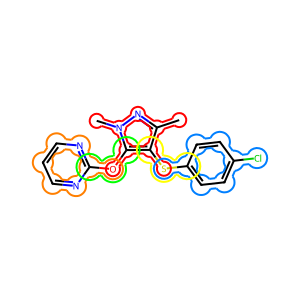

In [56]:
sf.to_image(safe_str)

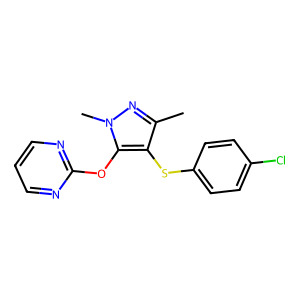

In [57]:
testreconstructed = dm.to_mol(safe_str)
display(dm.to_image(testreconstructed))

# Base Generation

Just a test generation to see if model is woring... basically the "de novo" way to generate molecules

In [62]:
result = gm.produce([m_seq], 100)

In [63]:
print(len(result))
print(result[0])
print(m_seq)

1
CC(C)[C@@H]1OCC[C@@H]1C(=O)N[C@H]1CCC[C@@H](Cn2ccnc2)C1
CC1=NN(C)C(OC2N=CC=CN=2)=C1SC1C=CC(Cl)=CC=1


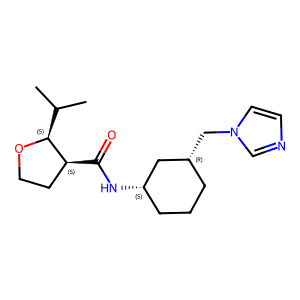

In [64]:
res_mol  = dm.to_mol(result[0])
display(dm.to_image(res_mol))

# Motif-Extension or Scaffold-Decoration

input is single fragment

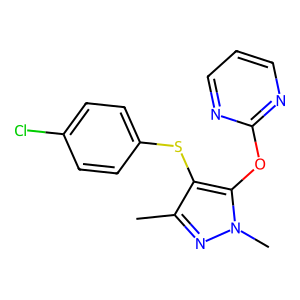

In [65]:
#draw original mol
smiles_full = m_seq
Draw.MolToImage(Chem.MolFromSmiles(smiles_full))

### Example 1: first fragment

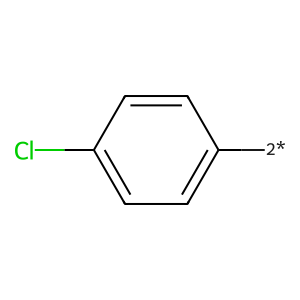

In [67]:
# add wildcard to a fragment
smiles_masked_1 = '[2*]C1=CC=C(Cl)C=C1'
Draw.MolToImage(Chem.MolFromSmiles(smiles_masked_1))

In [68]:
# generate with the masked smiels adding the wilcard to the ends
safe_to_gen = Utils.smiles2safe(smiles_masked_1)
safe_to_gen
molecules_e1 = gm.inference(smiles = safe_to_gen + '.[*{8-27}]', num_molecules = 100, temperature = 2.0, noise = 1.0)
len(molecules_e1)

17

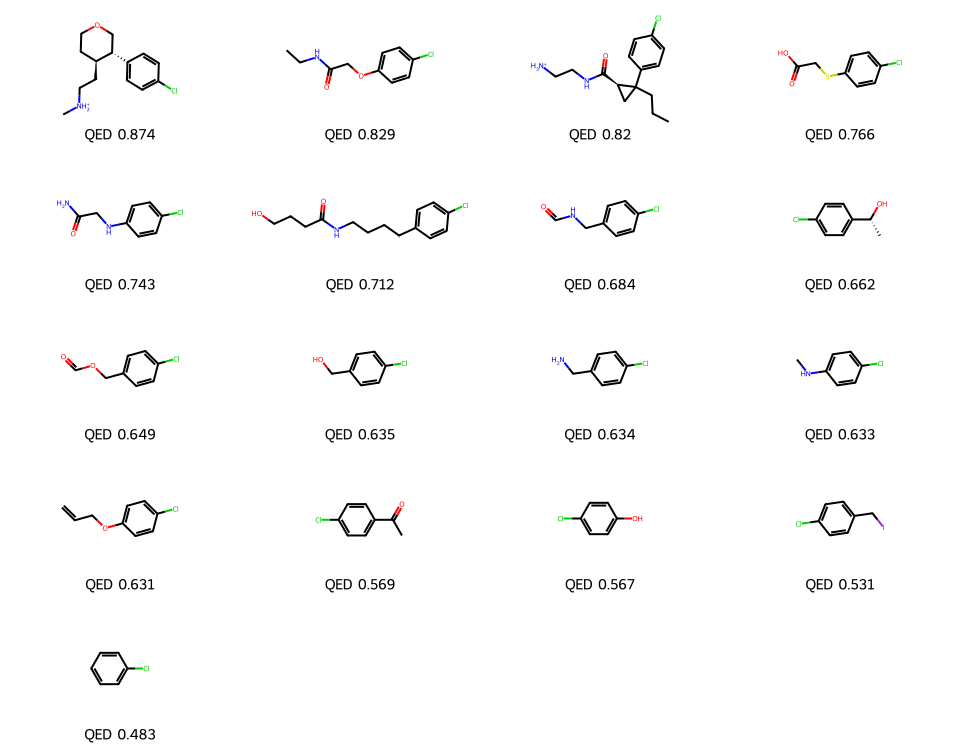

In [69]:
# Visualize the  molecules generated
ms = [Chem.MolFromSmiles(_['smiles']) for _ in molecules_e1]
Draw.MolsToGridImage(ms, molsPerRow=4, subImgSize=(240, 150), legends=['QED ' + str(_['score']) for _ in molecules_e1])

In [70]:
# Create a DataFrame + add results
df_results = pd.DataFrame(molecules_e1)

## Example 2: second fragment

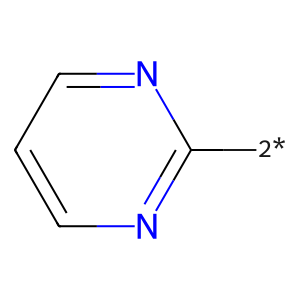

In [71]:
# add wildcard to a fragment
smiles_masked_2 = '[2*]C1=NC=CC=N1'
Draw.MolToImage(Chem.MolFromSmiles(smiles_masked_2))

In [72]:
# generate with the masked smiels adding the wilcard to the ends
safe_to_gen = Utils.smiles2safe(smiles_masked_2)
safe_to_gen
molecules_e2 = gm.inference(smiles = safe_to_gen + '.[*{10-28}]', num_molecules = 100, temperature = 2.0, noise = 1.0)
len(molecules_e2)

19

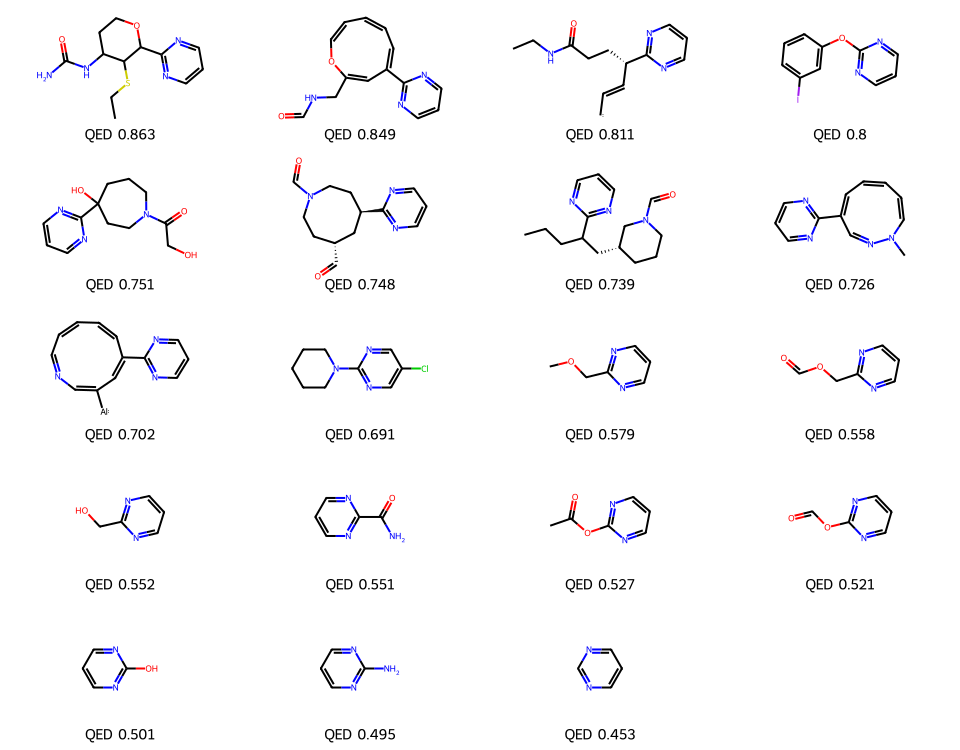

In [73]:
# Visualize the  molecules generated
ms = [Chem.MolFromSmiles(_['smiles']) for _ in molecules_e2]
Draw.MolsToGridImage(ms, molsPerRow=4, subImgSize=(240, 150), legends=['QED ' + str(_['score']) for _ in molecules_e2])

In [74]:
df_results = pd.concat([df_results, pd.DataFrame(molecules_e2)], ignore_index=True)

In [75]:
len(df_results)

36

## Example 3: third fragment

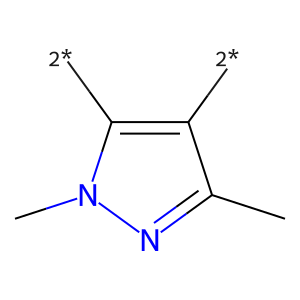

In [76]:
# add wildcard to a fragment
smiles_masked_3 = 'CN1N=C(C)C([2*])=C1[2*]'
Draw.MolToImage(Chem.MolFromSmiles(smiles_masked_3))

In [77]:
# generate with the masked smiels adding the wilcard to the ends
safe_to_gen = Utils.smiles2safe(smiles_masked_3)
safe_to_gen
molecules_e3 = gm.inference(smiles = safe_to_gen + '.[*{10-25}]', num_molecules = 100, temperature = 2.0, noise = 1.0)
len(molecules_e3)

75

/home/ec2-user/anaconda3/envs/python3/lib/python3.10/site-packages/rdkit/Chem/Draw/IPythonConsole.py:261: UserWarning: Truncating the list of molecules to be displayed to 50. Change the maxMols value to display more.
  warnings.warn(


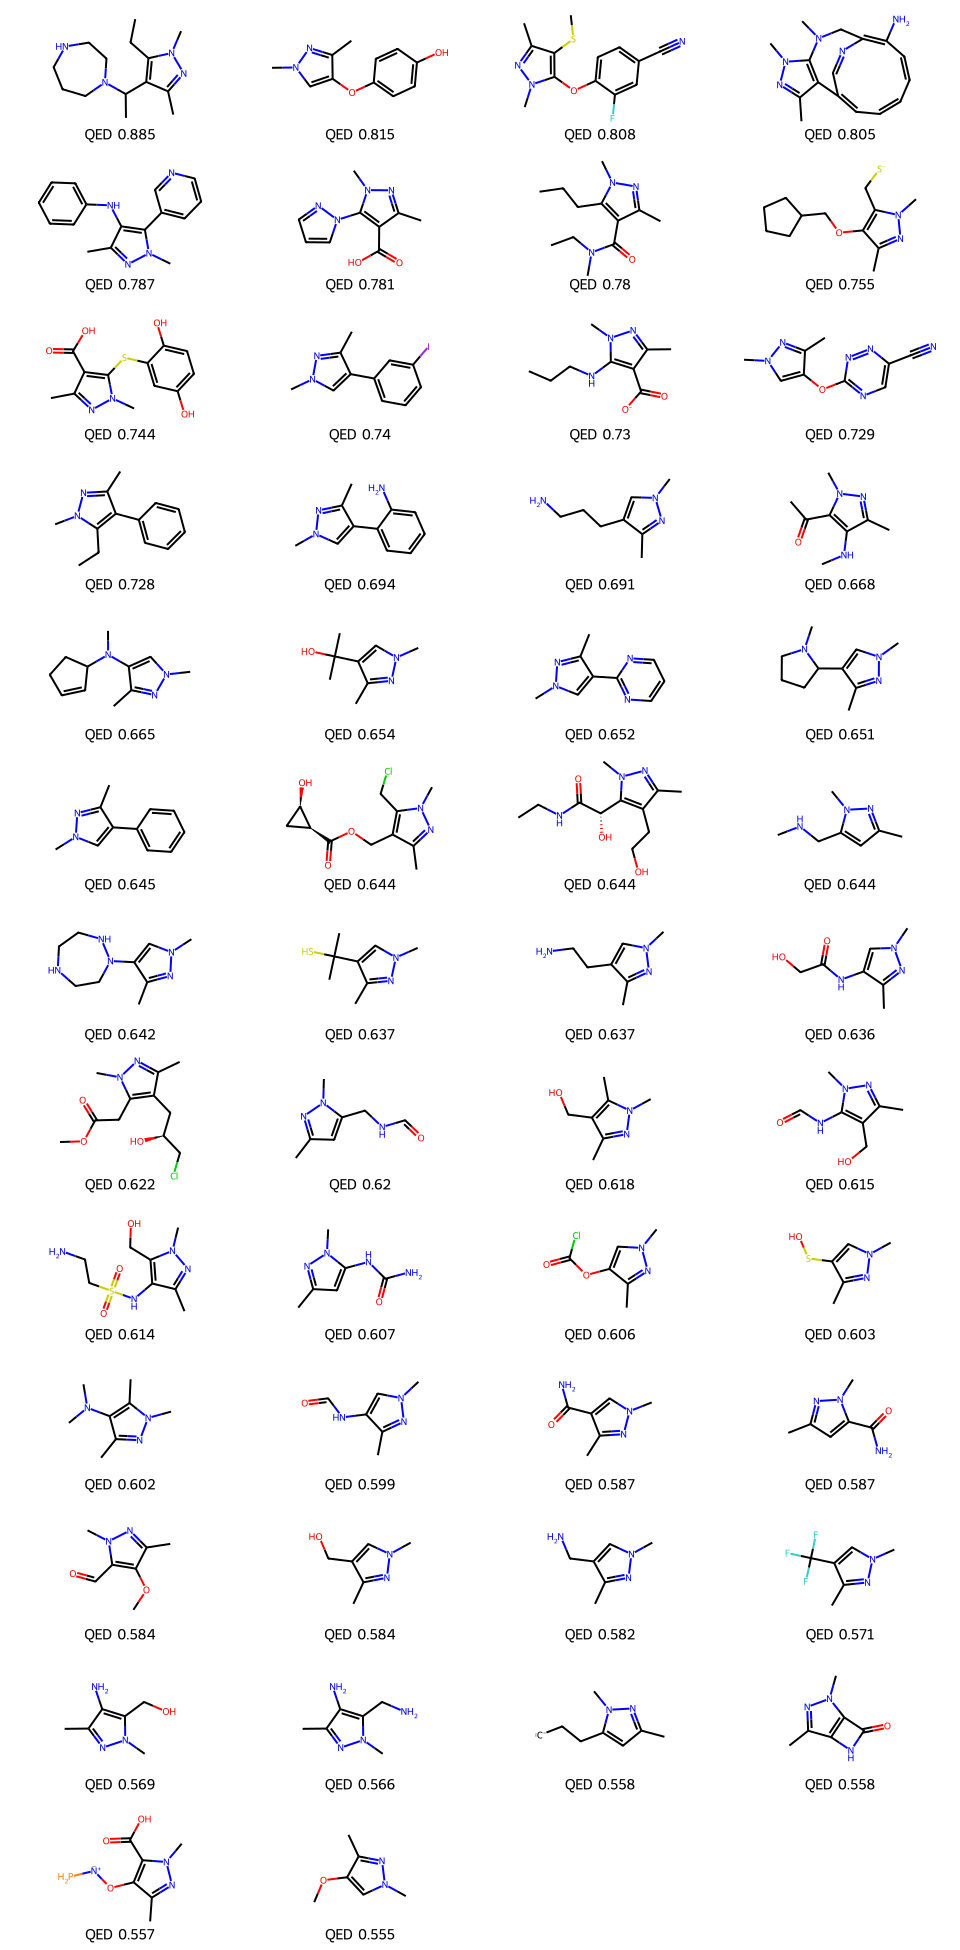

In [78]:
# Visualize the  molecules generated
ms = [Chem.MolFromSmiles(_['smiles']) for _ in molecules_e3]
Draw.MolsToGridImage(ms, molsPerRow=4, subImgSize=(240, 150), legends=['QED ' + str(_['score']) for _ in molecules_e3])

In [79]:
df_results = pd.concat([df_results, pd.DataFrame(molecules_e3)], ignore_index=True)

In [80]:
len(df_results)

111

# Fragment based generation 
(Linker generation / Scaffold morphing)

## Mask at the end

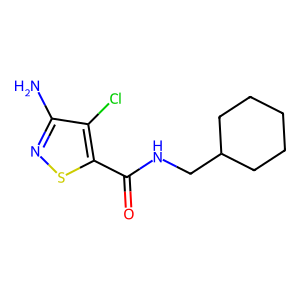

In [25]:
smiles_full = m_seq
Draw.MolToImage(Chem.MolFromSmiles(smiles_full))

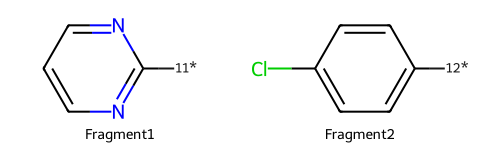

In [85]:
frag1, frag2 = '[11*]C1=NC=CC=N1', '[12*]C1=CC=C(Cl)C=C1'

Draw.MolsToGridImage([Chem.MolFromSmiles(frag1), Chem.MolFromSmiles(frag2)], 
                      molsPerRow=2, subImgSize=(240, 150), legends=['Fragment1', 'Fragment2'])

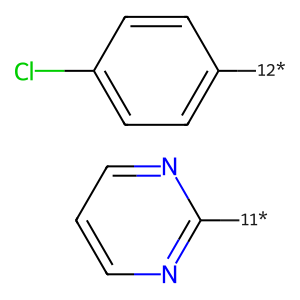

In [86]:
smiles_joint = '.'.join([frag1, frag2])
Draw.MolToImage(Chem.MolFromSmiles(smiles_joint))

In [91]:
# mask at the end
input_text = Utils.smiles2safe(smiles_joint) + '.[*{5-27}]'
input_text

'c13ccc(Cl)cc1.c12ncccn1.[*{5-27}]'

In [92]:
molecules_e4 = gm.inference(smiles=input_text, temperature =2.0, noise =1.0, num_molecules=1000, step_size=1)
len(molecules_e4)

20

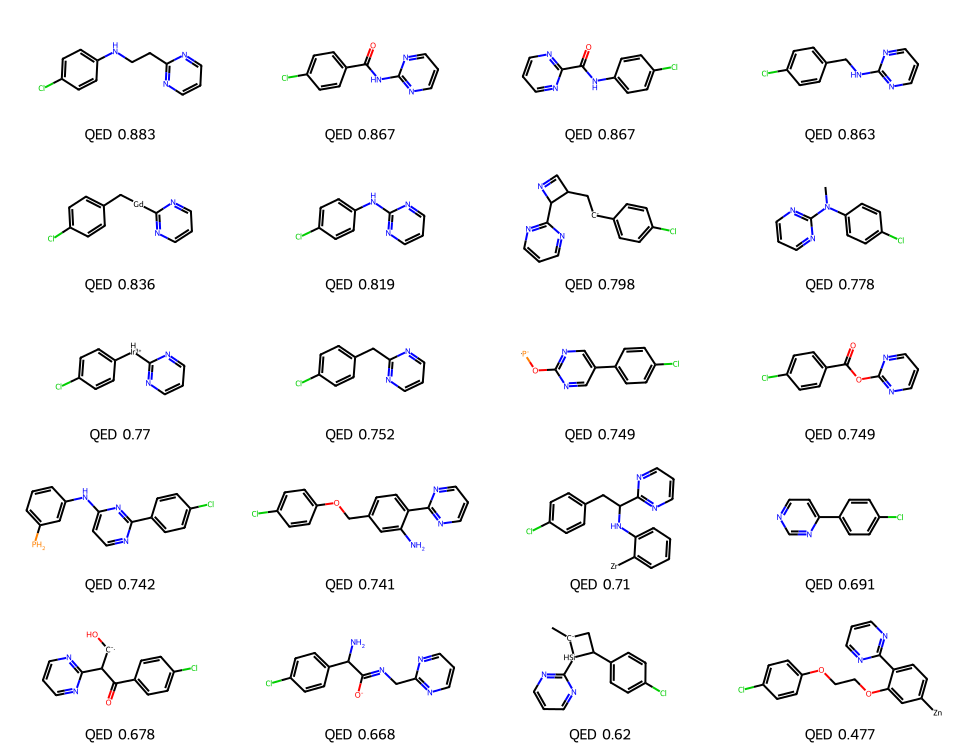

In [93]:
# Visualize the  molecules generated
ms = [Chem.MolFromSmiles(_['smiles']) for _ in molecules_e4]
Draw.MolsToGridImage(ms, molsPerRow=4, subImgSize=(240, 150), legends=['QED ' + str(_['score']) for _ in molecules_e4])

In [94]:
df_results = pd.concat([df_results, pd.DataFrame(molecules_e4)], ignore_index=True)
print(len(df_results))
df_results.head()

157


,smiles,score
0,C[NH2+]CC[C@H]1CCOC[C@@H]1c1ccc(Cl)cc1,0.874
1,CCNC(=O)COc1ccc(Cl)cc1,0.829
2,CCCC1(c2ccc(Cl)cc2)C[C@H]1C(=O)NCC[NH3+],0.820
3,O=C(O)CSc1ccc(Cl)cc1,0.766
4,NC(=O)CNc1ccc(Cl)cc1,0.743


## Mask in the center

[11*]C1=NC=CC=N1.[12*]C1=CC=C(Cl)C=C1


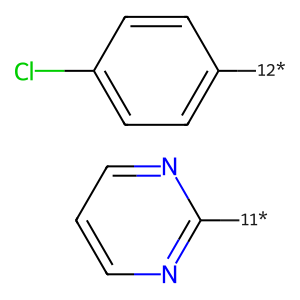

In [95]:
smiles_joint = '.'.join([frag1, frag2])
print(smiles_joint)
Draw.MolToImage(Chem.MolFromSmiles(smiles_joint))

In [96]:
#what sub-fragments are in frag1 
text_frag1 = Utils.smiles2safe(frag1).split('.')
text_frag1

['c12ncccn1']

In [97]:
#what sub-fragments are in frag2
text_frag2 = Utils.smiles2safe(frag2).split('.')
text_frag2

['c12ccc(Cl)cc1']

In [98]:
#what sub-fragments are in the full mol?
input_text = Utils.smiles2safe(smiles_joint).split('.')
input_text

['c13ccc(Cl)cc1', 'c12ncccn1']

In [99]:
input_text[:1]

['c13ccc(Cl)cc1']

In [100]:
# select where to set mask
input_w_mask = '.'.join(input_text[:1]) + '.[*{5-20}].' + '.'.join(input_text[1:])
input_w_mask

'c13ccc(Cl)cc1.[*{5-20}].c12ncccn1'

In [101]:
molecules_e5 = gm.inference(smiles = input_w_mask, temperature = 2.0, noise = 1.0, num_molecules=1000)
len(molecules_e5)

381

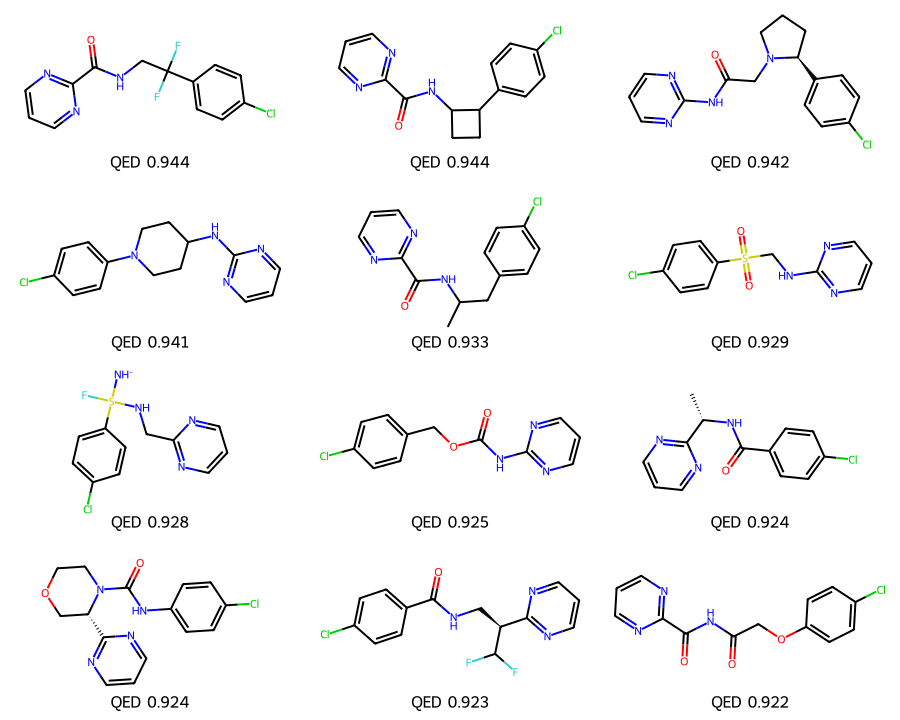

In [102]:
Draw.MolsToGridImage([Chem.MolFromSmiles(_['smiles']) for _ in molecules_e5[:12]], 
                      molsPerRow=3, subImgSize=(300, 180), legends=['QED ' + str(_['score']) for _ in molecules_e5[:12]])

In [103]:
df_results = pd.concat([df_results, pd.DataFrame(molecules_e5)], ignore_index=True)
print(len(df_results))
df_results.head()

538


,smiles,score
0,C[NH2+]CC[C@H]1CCOC[C@@H]1c1ccc(Cl)cc1,0.874
1,CCNC(=O)COc1ccc(Cl)cc1,0.829
2,CCCC1(c2ccc(Cl)cc2)C[C@H]1C(=O)NCC[NH3+],0.820
3,O=C(O)CSc1ccc(Cl)cc1,0.766
4,NC(=O)CNc1ccc(Cl)cc1,0.743


In [104]:
m1_name

'BCS-CM90960'

In [105]:
#df_results.to_csv(f"../../data/interim/genmol/{m1_name}_R1_testmulti.csv", index=False)